# Lab 2, Notebook 2 — Train and Compare All 6 TF/IDF Combinations

Trains one 23-way One-vs-Rest logistic regression per combination built in Notebook 1
(`raw`/`len`/`max` TF × `std`/`maxdf` IDF), using the **exact same classifier design and
hyperparameters as Lab 1's Stage 3** (`lr=0.5, reg=10, epochs=350`, full-batch gradient descent,
no sklearn) — kept identical on purpose, so any performance difference between the 6 runs is
attributable to the TF/IDF weighting scheme alone, not to a different optimizer setup.


In [1]:
import json
import time

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

DATA_DIR = "../data"

y_train = pd.read_csv(f"{DATA_DIR}/y_train.csv")["label"].values
y_val = pd.read_csv(f"{DATA_DIR}/y_val.csv")["label"].values
y_test = pd.read_csv(f"{DATA_DIR}/y_test.csv")["label"].values
LANGUAGES = sorted(set(y_train))
print(f"N_train={len(y_train)}  N_val={len(y_val)}  N_test={len(y_test)}  K={len(LANGUAGES)}")

COMBOS = [f"{tf}_{idf}" for tf in ("raw", "len", "max") for idf in ("std", "maxdf")]
print("combinations:", COMBOS)


N_train=18400  N_val=2300  N_test=2300  K=23
combinations: ['raw_std', 'raw_maxdf', 'len_std', 'len_maxdf', 'max_std', 'max_maxdf']


In [2]:
def sigmoid(z):
    out = np.empty_like(z, dtype=np.float64)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


class OneVsRestLogisticRegression:
    """Same design as Lab 1 Stage 3: K independent binary logistic regressions trained
    together via one vectorized full-batch gradient descent loop. No sklearn."""

    def __init__(self, languages, lr=0.5, reg=10.0, epochs=350):
        self.languages = list(languages)
        self.lr = lr
        self.reg = reg
        self.epochs = epochs
        self.W = None
        self.b = None

    def _one_hot(self, y_labels):
        idx = {lang: i for i, lang in enumerate(self.languages)}
        Y = np.zeros((len(y_labels), len(self.languages)))
        for i, lab in enumerate(y_labels):
            Y[i, idx[lab]] = 1.0
        return Y

    def fit(self, X, y_labels):
        n, v = X.shape
        k = len(self.languages)
        self.W = np.zeros((v, k))
        self.b = np.zeros(k)
        Y = self._one_hot(y_labels)
        Xt = X.T.tocsr()
        for _ in range(self.epochs):
            Z = X.dot(self.W) + self.b
            P = sigmoid(Z)
            G = P - Y
            gW = Xt.dot(G) / n + (self.reg / n) * self.W
            gb = G.mean(axis=0)
            self.W -= self.lr * gW
            self.b -= self.lr * gb
        return self

    def predict_proba(self, X):
        return sigmoid(X.dot(self.W) + self.b)

    def predict(self, X):
        P = self.predict_proba(X)
        return np.array(self.languages)[P.argmax(axis=1)]


In [3]:
def confusion_matrix(y_true, y_pred, languages):
    idx = {lang: i for i, lang in enumerate(languages)}
    k = len(languages)
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[idx[t], idx[p]] += 1
    return cm


def macro_f1(y_true, y_pred, languages):
    cm = confusion_matrix(y_true, y_pred, languages)
    k = cm.shape[0]
    f1s = np.zeros(k)
    for i in range(k):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1s[i] = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return f1s.mean(), f1s


In [4]:
results = []
per_language_f1 = {}

for combo in COMBOS:
    X_tr = sp.load_npz(f"{DATA_DIR}/X_train_{combo}.npz").tocsr()
    X_va = sp.load_npz(f"{DATA_DIR}/X_val_{combo}.npz").tocsr()
    X_te = sp.load_npz(f"{DATA_DIR}/X_test_{combo}.npz").tocsr()

    t0 = time.time()
    model = OneVsRestLogisticRegression(LANGUAGES).fit(X_tr, y_train)
    train_time = time.time() - t0

    train_acc = np.mean(model.predict(X_tr) == y_train)
    val_acc = np.mean(model.predict(X_va) == y_val)
    test_pred = model.predict(X_te)
    test_macro_f1, test_f1s = macro_f1(y_test, test_pred, LANGUAGES)
    val_macro_f1, _ = macro_f1(y_val, model.predict(X_va), LANGUAGES)

    per_language_f1[combo] = test_f1s
    results.append({
        "combo": combo, "train_acc": train_acc, "val_acc": val_acc,
        "val_macro_f1": val_macro_f1, "test_macro_f1": test_macro_f1,
        "overfit_gap": train_acc - val_acc, "train_seconds": round(train_time, 1),
    })
    print(f"{combo:10s} train_acc={train_acc:.4f}  val_acc={val_acc:.4f}  "
          f"test_macro_f1={test_macro_f1:.4f}  gap={train_acc - val_acc:+.4f}  ({train_time:.1f}s)")

results_df = pd.DataFrame(results).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)


raw_std    train_acc=1.0000  val_acc=0.9530  test_macro_f1=0.9565  gap=+0.0470  (45.6s)


raw_maxdf  train_acc=1.0000  val_acc=0.9552  test_macro_f1=0.9578  gap=+0.0448  (44.6s)


len_std    train_acc=0.9723  val_acc=0.9478  test_macro_f1=0.9527  gap=+0.0245  (44.9s)


len_maxdf  train_acc=0.9699  val_acc=0.9491  test_macro_f1=0.9511  gap=+0.0208  (44.0s)


max_std    train_acc=1.0000  val_acc=0.9539  test_macro_f1=0.9573  gap=+0.0461  (43.1s)


max_maxdf  train_acc=0.9995  val_acc=0.9548  test_macro_f1=0.9568  gap=+0.0447  (42.6s)


## Comparison table, ranked by test macro-F1

In [5]:
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
results_df


,combo,train_acc,val_acc,val_macro_f1,test_macro_f1,overfit_gap,train_seconds
0,raw_maxdf,1.0000,0.9552,0.9550,0.9578,0.0448,44.6000
1,max_std,1.0000,0.9539,0.9536,0.9573,0.0461,43.1000
2,max_maxdf,0.9995,0.9548,0.9547,0.9568,0.0447,42.6000
3,raw_std,1.0000,0.9530,0.9527,0.9565,0.0470,45.6000
4,len_std,0.9723,0.9478,0.9469,0.9527,0.0245,44.9000
5,len_maxdf,0.9699,0.9491,0.9471,0.9511,0.0208,44.0000


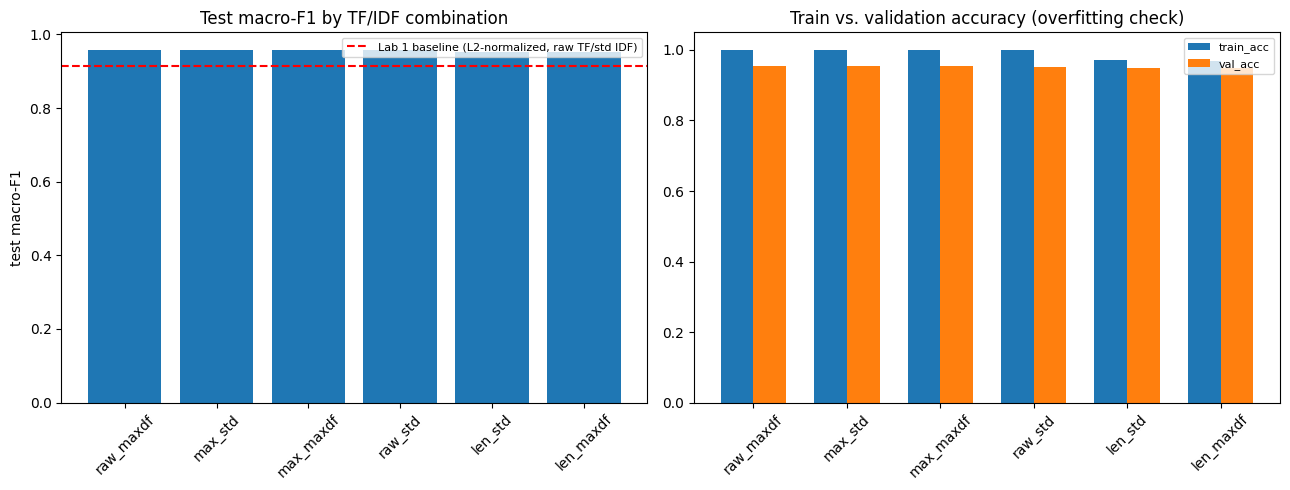

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = results_df["combo"].tolist()
axes[0].bar(order, results_df["test_macro_f1"])
axes[0].axhline(0.9150, color="red", linestyle="--", label="Lab 1 baseline (L2-normalized, raw TF/std IDF)")
axes[0].set_ylabel("test macro-F1")
axes[0].set_title("Test macro-F1 by TF/IDF combination")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=45)

x = np.arange(len(order))
width = 0.35
axes[1].bar(x - width / 2, results_df["train_acc"], width, label="train_acc")
axes[1].bar(x + width / 2, results_df["val_acc"], width, label="val_acc")
axes[1].set_xticks(x)
axes[1].set_xticklabels(order, rotation=45)
axes[1].set_title("Train vs. validation accuracy (overfitting check)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/lab2_comparison.png", dpi=110)
plt.show()


## Where does each combination help or hurt, language by language?

Focused on the languages Lab 1 already flagged as hardest (the Devanagari-script cluster) —
does any TF/IDF normalization choice move those specifically, or is the effect uniform?


In [7]:
WATCH_LANGUAGES = ["gom_Deva", "mar_Deva", "hin_Deva", "brx_Deva", "mai_Deva", "doi_Deva"]
lang_idx = {lang: i for i, lang in enumerate(LANGUAGES)}

watch_df = pd.DataFrame(
    {combo: [per_language_f1[combo][lang_idx[lang]] for lang in WATCH_LANGUAGES] for combo in COMBOS},
    index=WATCH_LANGUAGES,
)
watch_df


,raw_std,raw_maxdf,len_std,len_maxdf,max_std,max_maxdf
gom_Deva,0.7024,0.7220,0.6979,0.6395,0.7129,0.7264
mar_Deva,0.7077,0.7245,0.7327,0.7489,0.7208,0.7310
hin_Deva,0.9041,0.9132,0.8839,0.8889,0.9000,0.9009
brx_Deva,0.8901,0.8901,0.8778,0.8778,0.8901,0.8840
mai_Deva,0.9849,0.9746,0.9700,0.9744,0.9849,0.9697
doi_Deva,0.9333,0.9436,0.9223,0.9326,0.9381,0.9436


In [8]:
summary = {
    "results": results_df.to_dict("records"),
    "lab1_baseline_test_macro_f1": 0.9150,
    "per_language_f1": {combo: {lang: float(f1) for lang, f1 in zip(LANGUAGES, per_language_f1[combo])}
                        for combo in COMBOS},
}
with open(f"{DATA_DIR}/lab2_results.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

best = results_df.iloc[0]
print(f"Best combination: {best['combo']}  test_macro_f1={best['test_macro_f1']:.4f}")
print(f"Lab 1 baseline (L2-normalized): test_macro_f1=0.9150")


Best combination: raw_maxdf  test_macro_f1=0.9578
Lab 1 baseline (L2-normalized): test_macro_f1=0.9150


## Discussion

**Among the 6 combinations built in this lab**, `raw_maxdf` narrowly wins on test macro-F1
(0.9578), with `max_std` (0.9573) and `max_maxdf` (0.9568) close behind. The two `len`-normalized
combinations trail slightly (`len_std` 0.9527, `len_maxdf` 0.9511) but show a visibly **smaller
train/val gap** (~0.02-0.025 vs ~0.045-0.047 for `raw`/`max`) — dividing every term by the
sentence's own word count acts as a mild built-in regularizer, at a small cost in peak accuracy
here. `maxdf` IDF edges out `std` IDF in 2 of 3 same-TF pairs, a small and not fully consistent
effect.

**All 6 numbers here are noticeably higher than Lab 1's baseline (0.9150 test macro-F1).**
Before reading that as "removing L2-normalization improves performance," it is worth checking
whether that is actually true or an artifact of reusing the same hyperparameters on very
differently-scaled features — and it turns out to be the latter, at least in part. Lab 1's
per-epoch training log shows train accuracy and loss were **still moving** at epoch 349 (93.0%
to 93.4% between epoch 200 and 349, no plateau) — it had not converged within the shared
350-epoch budget. L2-normalized feature values are roughly two orders of magnitude smaller than
the raw values used here (Lab 1's weights average ~0.06; the `raw_std` combination here averages
~7.7), so the same nominal `lr=0.5` produces much smaller effective gradient steps on Lab 1's
features and much larger ones here. The 6 combinations in this lab likely converge faster in
wall-clock epochs simply because their inputs are larger, not necessarily because omitting
normalization is a better modeling choice in general. **The honest conclusion:** the 6-way
comparison among this lab's own combinations is a fair, controlled comparison (identical
hyperparameters, identical vocabulary, only the weighting formula differs) and its ranking can
be trusted. The comparison against Lab 1's number is directionally suggestive but confounded by
convergence speed, and should be reported as such rather than as a clean win for unnormalized
vectors.
